# 4. Cenários de temperatura e alimentação

> **Os dados deste projeto são SIMULADOS** (ver notebook 01). Os cenários são previsões do modelo, não observações.

Perguntas:
1. Quantos dias demora cada espécie a chegar ao **tamanho comercial de 400 g** com a água a **16, 20 e 24 °C**?
2. O que acontece se dermos **menos ração** do que a saciedade?
3. Que espécie é mais sensível a cada fator?

Para isto usamos o modelo com temperatura do notebook 01 (modelo TGC, com a temperatura acumulada acima de 12 °C) e não a curva de von Bertalanffy, que não inclui a temperatura (notebook 03).

In [1]:
import sys
sys.path.append("..")   # para o Python encontrar a pasta src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.growth import (PARAMETROS, PESO_INICIAL_G, CENARIOS_ALIMENTACAO,
                        simular_ciclo, dias_ate_peso)

sns.set_theme(style="whitegrid", context="notebook")
CORES = {"dourada": "#c9971c", "robalo": "#3f6ea6"}
NOMES = {"dourada": "Dourada (Sparus aurata)", "robalo": "Robalo (Dicentrarchus labrax)"}
ESPECIES = ["dourada", "robalo"]

TEMPERATURAS = [16, 20, 24]   # °C
PESO_COMERCIAL = 400          # g
N_DIAS = 1300                 # chega para todos os cenários atingirem os 400 g
N_PEIXES = 5000

## 4.1 Como são feitos os cenários

- **Temperatura constante** durante todo o ciclo (16, 20 ou 24 °C), em vez da curva sazonal do notebook 01. Não é realista (a temperatura do mar varia ao longo do ano), mas isola o efeito da temperatura. 24 °C está dentro do limite de validade do modelo (25 °C).
- Tudo o resto é igual à simulação do notebook 01: 5 000 juvenis de 3 g, variação individual, mortalidade diária e a mesma semente aleatória.
- **Alimentação:** usamos dois estudos que compararam peixes alimentados até à **saciedade** com peixes que receberam **menos ração**. Aplicamos ao modelo a variação relativa do crescimento e do FCR observada em cada estudo:

In [2]:
linhas = []
for especie in ESPECIES:
    for nome, cen in CENARIOS_ALIMENTACAO[especie].items():
        linhas.append({"espécie": especie, "alimentação": nome,
                       "ração": cen.get("descricao", "até à saciedade"),
                       "fator de crescimento": cen["fator_crescimento"],
                       "fator de FCR": cen["fator_fcr"]})
pd.DataFrame(linhas).set_index(["espécie", "alimentação"])

ração  fator de crescimento  fator de FCR
espécie alimentação                                                       
dourada saciedade      até à saciedade                  1.00          1.00
        restrita     80 % da saciedade                  0.92          0.83
robalo  saciedade      até à saciedade                  1.00          1.00
        restrita     75 % da saciedade                  0.88          1.00

| Espécie | Estudo | O que mediram | Fatores |
|---|---|---|---|
| Dourada | Bonaldo et al. (2010), *Aquaculture International* 18: 909–919 | Peixes de 73 g, 81 dias a 24 °C: saciedade vs. 80 % da saciedade | SGR 1,50 → 1,37 %/dia (× 0,92); FCR 1,37 → 1,14 (× 0,83) |
| Robalo | Türkmen et al. (2012), *Aquaculture Research* 43: 1643–1650 | Juvenis de 10,5 g: saciedade vs. alimentação 25 % restrita | SGR 2,5 → 2,2 %/dia (× 0,88); FCR sem diferença significativa (× 1,0) |

As SGR da dourada foram calculadas por nós a partir dos pesos inicial e final da Tabela 2 do artigo (médias das três dietas).

**Cuidado:** os dois estudos usaram peixes pequenos, em tanques, durante poucos meses. Aplicar os fatores a um ciclo inteiro de engorda é uma **extrapolação**. Além disso, o fator de crescimento multiplica o TGC do modelo, o que dá uma redução da SGR aproximadamente (não exatamente) igual à do estudo.

## 4.2 Correr os cenários

3 temperaturas × 2 alimentações × 2 espécies = 12 simulações.

In [3]:
simulacoes = {}
linhas = []
for especie in ESPECIES:
    fcr_base = PARAMETROS[especie]["fcr"]
    for temperatura in TEMPERATURAS:
        for alimentacao, cen in CENARIOS_ALIMENTACAO[especie].items():
            sim = simular_ciclo(especie, n_dias=N_DIAS, n_peixes=N_PEIXES,
                                temperatura=np.full(N_DIAS, temperatura),
                                fator_crescimento=cen["fator_crescimento"],
                                fcr=fcr_base * cen["fator_fcr"], semente=42)
            simulacoes[(especie, temperatura, alimentacao)] = sim

            # Indicadores até ao dia em que o peso médio chega aos 400 g
            dia = dias_ate_peso(sim, PESO_COMERCIAL)
            ate_400 = sim.loc[:dia]
            biomassa_inicial = N_PEIXES * PESO_INICIAL_G / 1000
            biomassa_final = ate_400["biomassa_kg"].iloc[-1]
            racao = ate_400["racao_kg"].sum()
            linhas.append({
                "espécie": especie,
                "temperatura (°C)": temperatura,
                "alimentação": alimentacao,
                "dias até 400 g": dia,
                "meses até 400 g": round(dia / 30.4, 1),
                "sobrevivência (%)": round(sim.loc[dia, "n_peixes"] / N_PEIXES * 100, 1),
                "biomassa final (kg)": round(biomassa_final),
                "ração total (kg)": round(racao),
                "FCR económico": round(racao / (biomassa_final - biomassa_inicial), 2),
            })

cenarios = pd.DataFrame(linhas)
cenarios.set_index(["espécie", "temperatura (°C)", "alimentação"])

dias até 400 g  meses até 400 g  \
espécie temperatura (°C) alimentação                                    
dourada 16               saciedade               992             32.6   
                         restrita               1079             35.5   
        20               saciedade               496             16.3   
                         restrita                539             17.7   
        24               saciedade               331             10.9   
                         restrita                359             11.8   
robalo  16               saciedade              1132             37.2   
                         restrita               1287             42.3   
        20               saciedade               565             18.6   
                         restrita                643             21.2   
        24               saciedade               377             12.4   
                         restrita                428             14.1   

                                      sobrevivência (%)  biomassa final (kg)  \
espécie temperatura (°C) alimentação                                           
dourada 16               saciedade                 61.3                 1228   
                         restrita                  58.7                 1176   
        20               saciedade                 78.6                 1575   
                         restrita                  76.9                 1543   
        24               saciedade                 85.3                 1714   
                         restrita                  84.0                 1680   
robalo  16               saciedade                 69.8                 1396   
                         restrita                  66.8                 1337   
        20               saciedade                 83.5                 1672   
                         restrita                  81.6                 1637   
        24               saciedade                 88.9                 1781   
                         restrita                  87.3                 1746   

                                      ração total (kg)  FCR económico  
espécie temperatura (°C) alimentação                                   
dourada 16               saciedade                3065           2.53  
                         restrita                 2480           2.14  
        20               saciedade                3588           2.30  
                         restrita                 2928           1.92  
        24               saciedade                3825           2.25  
                         restrita                 3133           1.88  
robalo  16               saciedade                3426           2.48  
                         restrita                 3318           2.51  
        20               saciedade                3850           2.32  
                         restrita                 3787           2.33  
        24               saciedade                4082           2.31  
                         restrita                 3999           2.31

## 4.3 Efeito da temperatura

Primeiro só com alimentação até à saciedade.

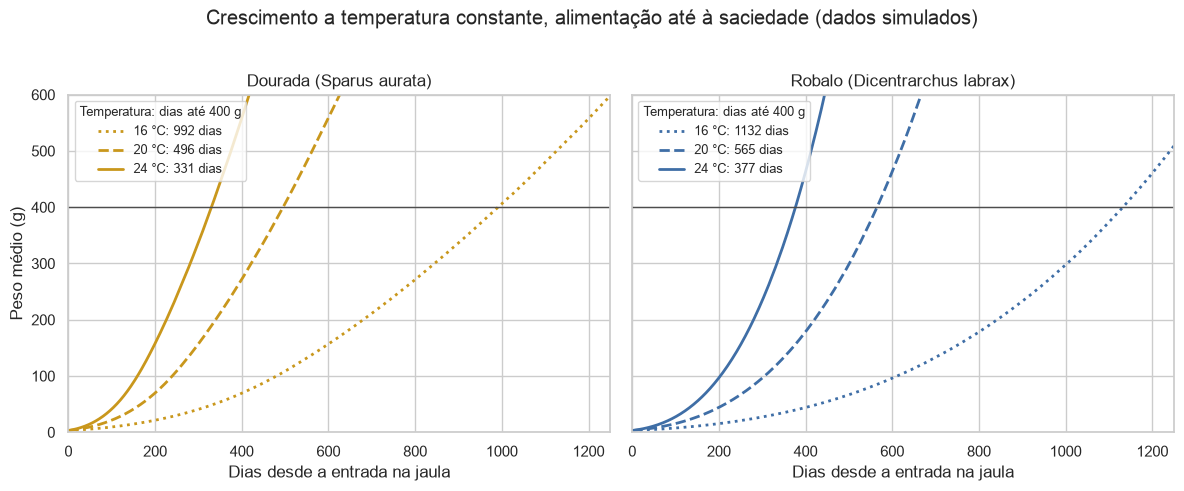

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
estilos = {16: ":", 20: "--", 24: "-"}
for ax, especie in zip(axes, ESPECIES):
    for temperatura in TEMPERATURAS:
        sim = simulacoes[(especie, temperatura, "saciedade")]
        dia = dias_ate_peso(sim, PESO_COMERCIAL)
        ax.plot(sim["dia"], sim["peso_medio_g"], color=CORES[especie], linestyle=estilos[temperatura],
                linewidth=2, label=f"{temperatura} °C: {dia} dias")
    ax.axhline(PESO_COMERCIAL, color="0.3", linewidth=1)
    ax.set_ylim(0, 600)
    ax.set_xlim(0, 1250)
    ax.set_title(NOMES[especie])
    ax.set_xlabel("Dias desde a entrada na jaula")
    ax.legend(title="Temperatura: dias até 400 g", fontsize=9, title_fontsize=9, loc="upper left")
axes[0].set_ylabel("Peso médio (g)")
fig.suptitle("Crescimento a temperatura constante, alimentação até à saciedade (dados simulados)", y=1.02)
plt.tight_layout()
plt.savefig("../figures/04_temperatura.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
saciedade = cenarios[cenarios["alimentação"] == "saciedade"]
tabela = saciedade.pivot(index="temperatura (°C)", columns="espécie", values="dias até 400 g")
tabela["diferença (dias)"] = tabela["robalo"] - tabela["dourada"]
tabela

espécie,dourada,robalo,diferença (dias)
temperatura (°C),,,
16,992,1132,140
20,496,565,69
24,331,377,46


In [6]:
# Quanto se ganha com +4 °C?
for especie in ESPECIES:
    dias = tabela[especie]
    print(f"{especie}: 16→20 °C poupa {dias[16] - dias[20]} dias ({(1 - dias[20] / dias[16]):.0%}); "
          f"20→24 °C poupa {dias[20] - dias[24]} dias ({(1 - dias[24] / dias[20]):.0%})")

# No modelo TGC o crescimento é proporcional à temperatura efetiva (T - 12)
for t1, t2 in [(16, 20), (20, 24)]:
    print(f"{t1}→{t2} °C: temperatura efetiva de {t1 - 12} para {t2 - 12} graus-dia por dia (× {(t2 - 12) / (t1 - 12):.2f})")

dourada: 16→20 °C poupa 496 dias (50%); 20→24 °C poupa 165 dias (33%)
robalo: 16→20 °C poupa 567 dias (50%); 20→24 °C poupa 188 dias (33%)
16→20 °C: temperatura efetiva de 4 para 8 graus-dia por dia (× 2.00)
20→24 °C: temperatura efetiva de 8 para 12 graus-dia por dia (× 1.50)


**Leitura:**
- Com água mais quente, as duas espécies chegam muito mais cedo aos 400 g. Entre 16 e 24 °C o ciclo da dourada passa de **≈ 33 para ≈ 11 meses**, e o do robalo de **≈ 37 para ≈ 12 meses**.
- O efeito **não é igual em cada grau**: de 16 para 20 °C o ciclo encurta para metade (− 50 %), de 20 para 24 °C encurta um terço (− 33 %). No modelo TGC só conta a temperatura acima de 12 °C: a 16 °C o peixe recebe 4 graus-dia por dia, a 20 °C recebe 8 (o dobro) e a 24 °C recebe 12 (mais 50 %). Por isso **cada grau vale mais quando a água está fria**.
- As duas espécies respondem **na mesma proporção** à temperatura (as mesmas percentagens), porque usam a mesma temperatura base de 12 °C. No robalo esta temperatura base é um **pressuposto**: se fosse mais baixa, o robalo seria menos sensível ao frio.
- A **dourada é sempre mais rápida**, cerca de 12–14 % menos dias do que o robalo, o que dá 46 dias a 24 °C e 140 dias a 16 °C.
- A sobrevivência aos 400 g é **mais alta** com água quente, mas só porque o ciclo é mais curto (no modelo, a probabilidade de morrer por dia é a mesma a qualquer temperatura).

**Cuidado com os 16 °C constantes:** o TGC de Mayer et al. (2012) foi ajustado em jaulas com a temperatura a variar entre 13 e 26,5 °C ao longo do ano. Um ano inteiro a 16 °C fica fora dessas condições, e a relação linear com a temperatura efetiva pode subestimar o crescimento a essa temperatura. O resultado de ≈ 33 meses deve ser lido como **extrapolação**.

**Limite importante:** no modelo o crescimento aumenta sempre com a temperatura. Na realidade, acima da temperatura ótima o crescimento diminui (para o robalo, o ótimo é de cerca de 26 °C; Person-Le Ruyet et al., 2004). Por isso não simulamos acima de 25 °C.

## 4.4 Efeito da alimentação

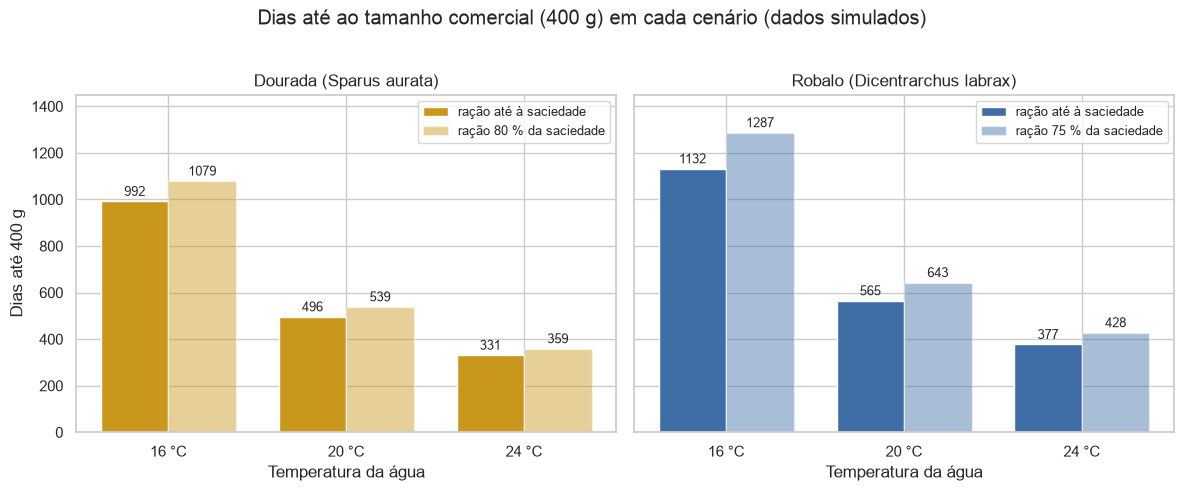

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
largura = 0.38
for ax, especie in zip(axes, ESPECIES):
    dados = cenarios[cenarios["espécie"] == especie]
    for i, (alimentacao, transparencia) in enumerate([("saciedade", 1.0), ("restrita", 0.45)]):
        d = dados[dados["alimentação"] == alimentacao]
        x = np.arange(len(TEMPERATURAS)) + (i - 0.5) * largura
        descricao = CENARIOS_ALIMENTACAO[especie][alimentacao].get("descricao", "até à saciedade")
        barras = ax.bar(x, d["dias até 400 g"], width=largura, color=CORES[especie],
                        alpha=transparencia, label=f"ração {descricao}")
        ax.bar_label(barras, fontsize=9, padding=2)
    ax.set_xticks(range(len(TEMPERATURAS)), [f"{t} °C" for t in TEMPERATURAS])
    ax.set_title(NOMES[especie])
    ax.set_xlabel("Temperatura da água")
    ax.legend(fontsize=9, loc="upper right")
axes[0].set_ylabel("Dias até 400 g")
axes[0].set_ylim(0, 1450)
fig.suptitle("Dias até ao tamanho comercial (400 g) em cada cenário (dados simulados)", y=1.02)
plt.tight_layout()
plt.savefig("../figures/04_dias_ate_400g.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
comparacao = cenarios.pivot_table(index=["espécie", "temperatura (°C)"], columns="alimentação",
                                  values=["dias até 400 g", "FCR económico"])
comparacao

FCR económico           dias até 400 g          
alimentação                   restrita saciedade       restrita saciedade
espécie temperatura (°C)                                                 
dourada 16                        2.14      2.53         1079.0     992.0
        20                        1.92      2.30          539.0     496.0
        24                        1.88      2.25          359.0     331.0
robalo  16                        2.51      2.48         1287.0    1132.0
        20                        2.33      2.32          643.0     565.0
        24                        2.31      2.31          428.0     377.0

### Tempo ou ração? O compromisso

Cada ponto é um cenário. O ideal seria estar no canto inferior esquerdo (poucos dias e pouca ração por kg de peixe).

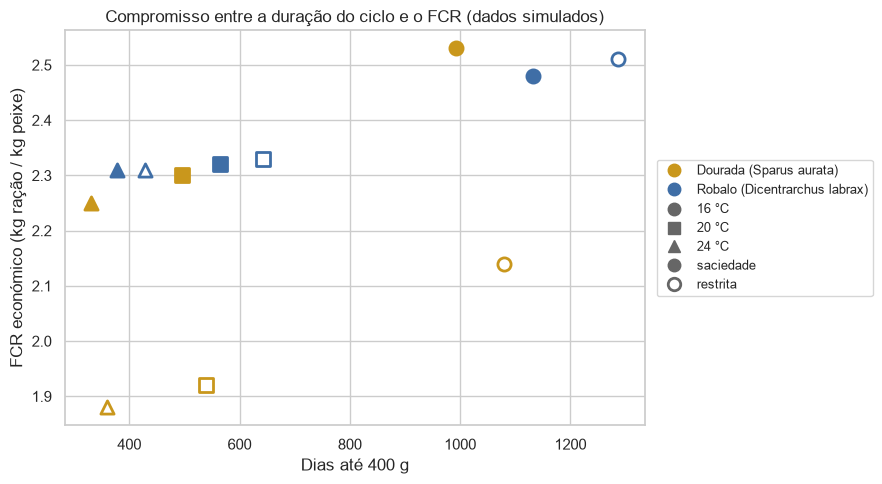

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
marcadores = {16: "o", 20: "s", 24: "^"}
for _, linha in cenarios.iterrows():
    cheio = linha["alimentação"] == "saciedade"
    ax.scatter(linha["dias até 400 g"], linha["FCR económico"], s=90,
               marker=marcadores[linha["temperatura (°C)"]],
               color=CORES[linha["espécie"]] if cheio else "white",
               edgecolor=CORES[linha["espécie"]], linewidth=2)

# Legenda feita à mão: cor = espécie, forma = temperatura, cheio/vazio = alimentação
from matplotlib.lines import Line2D
legenda = ([Line2D([], [], marker="o", linestyle="", color=CORES[e], markersize=9, label=NOMES[e]) for e in ESPECIES]
           + [Line2D([], [], marker=marcadores[t], linestyle="", color="0.4", markersize=9, label=f"{t} °C") for t in TEMPERATURAS]
           + [Line2D([], [], marker="o", linestyle="", color="0.4", markersize=9, label="saciedade"),
              Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="0.4",
                     markeredgewidth=2, markersize=9, label="restrita")])
ax.legend(handles=legenda, fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_title("Compromisso entre a duração do ciclo e o FCR (dados simulados)")
ax.set_xlabel("Dias até 400 g")
ax.set_ylabel("FCR económico (kg ração / kg peixe)")
plt.tight_layout()
plt.savefig("../figures/04_compromisso.png", dpi=150)
plt.show()

**Leitura:**
- **Dourada:** a ração restrita (80 %) atrasa o ciclo cerca de 9 % (28 a 87 dias, conforme a temperatura), mas **baixa o FCR económico de cerca de 2,3 para 1,9**: produzir o mesmo peixe gasta cerca de 16 % menos ração. Isto está de acordo com Bonaldo et al. (2010), que concluíram que a alimentação a 80 % era a opção mais rentável.
- **Robalo:** a ração restrita (75 %) atrasa o ciclo cerca de 14 % (51 a 155 dias) e **não melhora o FCR**, porque no estudo de referência (Türkmen et al., 2012) o FCR não mudou. Para o robalo, restringir a ração só faz perder tempo.
- Com água fria (16 °C) o FCR económico é mais alto em todos os cenários (≈ 2,5 em vez de ≈ 2,3): o ciclo é tão longo que morrem mais peixes antes da despesca, e a ração que comeram perde-se.
- O que é melhor depende da **economia da exploração**: na dourada, poupar ração compensa se o custo de ter os peixes mais tempo na água (mão de obra, risco de doenças, ocupação da jaula) for menor do que o valor da ração poupada. A app do projeto faz essa conta com os preços introduzidos.

## 4.5 Conclusões

| | Dourada | Robalo |
|---|---|---|
| Dias até 400 g a 16 / 20 / 24 °C (saciedade) | 992 / 496 / 331 | 1 132 / 565 / 377 |
| Redução do ciclo de 16 → 20 °C / 20 → 24 °C | − 50 % / − 33 % | − 50 % / − 33 % |
| Efeito da ração restrita no tempo | + 9 % | + 14 % |
| Efeito da ração restrita no FCR | 2,3 → 1,9 | sem melhoria |

1. A **temperatura** é o fator com mais efeito, e cada grau vale mais quando a água está fria: no modelo TGC o crescimento é proporcional à temperatura acima de 12 °C.
2. A **dourada chega aos 400 g cerca de 12–14 % mais cedo** do que o robalo em qualquer temperatura (esta diferença vem da calibração do TGC do robalo, notebook 01).
3. **Restringir a ração** poupa ração na dourada, à custa de um ciclo mais longo; no robalo só atrasa o ciclo.

**Limitações:**
- Temperatura constante (na realidade é sazonal) e sem temperatura ótima no modelo; a 16 °C constantes o modelo está fora das condições em que foi ajustado.
- A temperatura base de 12 °C no robalo e o seu TGC são pressupostos/calibração, não valores publicados.
- Mortalidade igual a qualquer temperatura e alimentação; na realidade temperaturas extremas e stress alimentar podem aumentá-la.
- Os efeitos da alimentação vêm de ensaios curtos com juvenis em tanques e foram extrapolados para o ciclo inteiro; para o robalo, assumimos FCR igual porque o estudo não encontrou diferença significativa.
- Não incluímos o crescimento compensatório (peixes que recuperam depois de um período de restrição).